# Évaluation complète du modèle YOLOv8-seg (`wiring_harness_connectors_seg`)

Ce notebook calcule et affiche un maximum de métriques d'évaluation pour votre modèle de segmentation d'instance entraîné sur **`wiring harness connectors segmen.v1i.yolov8`** :
- **Métriques Ultralytics globales et par classe** (sur `val` et `test`) : `Precision (B/M)`, `Recall (B/M)`, `F1-score`, `mAP50 (B/M)`, `mAP50-95 (B/M)`, `Fitness`.
- **Métriques de segmentation au pixel près** : `IoU` moyen/médian, `Dice coefficient` (`F1` pixel), `Precision` et `Recall` pixel, `Pixel Accuracy`.
- **Analyse par seuil de confiance (`conf`)** : courbe `Precision`, `Recall` et `F1` en fonction du seuil de confiance pour trouver le seuil optimal.
- **Temps d'inférence et latence** : temps moyen/médian/P95 par image et FPS (`images/s`), taille du fichier `.pt`.
- **Visualisations** : barplot des `mAP50` et `mAP50-95` par classe, courbes `P/R/F1 vs conf`, et galerie de prédictions (masques + boîtes + scores).

## Bloc 1 — Configuration des chemins et chargement de `best.pt`

In [1]:
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from ultralytics import YOLO

# Adaptez si votre dossier d'entraînement porte un suffixe (ex. wiring_harness_connectors_seg2)
BEST_WEIGHTS = Path(r"D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation_paliers/best_ep100.pt").resolve()
DATA_YAML = Path(r"D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\data.yaml").resolve()

if not BEST_WEIGHTS.exists():
    # Recherche automatique du dernier best.pt si nécessaire
    candidates = sorted(Path(r"D:\S5\Projet_d_expertise\projet\models").glob("**/best.pt"), key=lambda p: p.stat().st_mtime, reverse=True)
    if candidates:
        BEST_WEIGHTS = candidates[0].resolve()
        print(f"best.pt trouvé automatiquement : {BEST_WEIGHTS}")
    else:
        raise FileNotFoundError(f"Fichier best.pt introuvable : {BEST_WEIGHTS}")

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Fichier data.yaml introuvable : {DATA_YAML}")

with open(DATA_YAML, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

model = YOLO(str(BEST_WEIGHTS))
size_mb = BEST_WEIGHTS.stat().st_size / (1024 * 1024)
print(f"Modèle chargé : {BEST_WEIGHTS} ({size_mb:.2f} Mo)")
print(f"Classes ({len(model.names)}) : {model.names}")

Modèle chargé : D:\S5\Projet_d_expertise\projet\models\01_detection_et_segmentation_paliers\best_ep100.pt (6.46 Mo)
Classes (5) : {0: 'cable', 1: 'cable-tie', 2: 'clip', 3: 'connector', 4: 'label'}


## Bloc 2 — Métriques globales Ultralytics (`val` et `test` : Box & Mask `P`, `R`, `F1`, `mAP50`, `mAP50-95`)

In [2]:
def extract_global_metrics(val_res, split_name: str) -> list[dict]:
    rows = []
    # Box metrics
    b_p = float(val_res.box.mp)
    b_r = float(val_res.box.mr)
    b_f1 = (2 * b_p * b_r / (b_p + b_r)) if (b_p + b_r) > 0 else 0.0
    rows.append({
        "split": split_name,
        "modality": "Box (Détection)",
        "Precision": round(b_p, 4),
        "Recall": round(b_r, 4),
        "F1_score": round(b_f1, 4),
        "mAP50": round(float(val_res.box.map50), 4),
        "mAP50_95": round(float(val_res.box.map), 4),
        "fitness": round(float(val_res.fitness), 4) if hasattr(val_res, "fitness") else None,
    })
    # Mask metrics
    if getattr(val_res, "seg", None) is not None:
        m_p = float(val_res.seg.mp)
        m_r = float(val_res.seg.mr)
        m_f1 = (2 * m_p * m_r / (m_p + m_r)) if (m_p + m_r) > 0 else 0.0
        rows.append({
            "split": split_name,
            "modality": "Mask (Segmentation)",
            "Precision": round(m_p, 4),
            "Recall": round(m_r, 4),
            "F1_score": round(m_f1, 4),
            "mAP50": round(float(val_res.seg.map50), 4),
            "mAP50_95": round(float(val_res.seg.map), 4),
            "fitness": round(float(val_res.fitness), 4) if hasattr(val_res, "fitness") else None,
        })
    return rows

val_metrics = model.val(data=str(DATA_YAML), split="val", imgsz=640, batch=8, workers=0, plots=False, verbose=False)
all_global = extract_global_metrics(val_metrics, "val")

# Évaluation sur 'test' si présent dans data.yaml
test_metrics = None
if "test" in data_cfg:
    try:
        test_metrics = model.val(data=str(DATA_YAML), split="test", imgsz=640, batch=8, workers=0, plots=False, verbose=False)
        all_global.extend(extract_global_metrics(test_metrics, "test"))
    except Exception as e:
        print(f"Évaluation sur 'test' ignorée : {e}")

df_global = pd.DataFrame(all_global)
display(df_global)

Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,259,039 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access  (ping: 0.10.1 ms, read: 57.922.1 MB/s, size: 32.6 KB)
val: Scanning D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.6s/it 7.7s5.2ss
                   all         22        106      0.899      0.667      0.753      0.566       0.83      0.661      0.718       0.55
Speed: 2.1ms preprocess, 250.1ms inference, 0.0ms loss, 67.3ms postprocess per image
Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
val: Fast image access  (ping: 0.10.1 ms, read: 50.221.2 MB/s, size: 38.4 KB)

,split,modality,Precision,Recall,F1_score,mAP50,mAP50_95,fitness
0,val,Box (Détection),0.8990,0.6674,0.7661,0.7532,0.5660,1.1159
1,val,Mask (Segmentation),0.8298,0.6606,0.7356,0.7179,0.5499,1.1159
2,test,Box (Détection),0.4764,0.6528,0.5508,0.5868,0.4759,0.9754
3,test,Mask (Segmentation),0.5250,0.7292,0.6105,0.6432,0.4995,0.9754


## Bloc 3 — Métriques détaillées par classe (`Box` et `Mask`)

,class_id,class_name,Box_P,Box_R,Box_F1,Box_mAP50,Box_mAP50_95,Mask_P,Mask_R,Mask_F1,Mask_mAP50,Mask_mAP50_95
0,0,cable,1.0000,0.0551,0.1044,0.2597,0.1206,0.6543,0.0323,0.0615,0.0999,0.0607
1,1,cable-tie,1.0000,0.8338,0.9094,0.9950,0.7959,1.0000,0.8303,0.9073,0.9950,0.7960
2,2,clip,0.7906,0.7625,0.7763,0.6899,0.4931,0.7888,0.7553,0.7717,0.6899,0.4421
3,3,connector,0.8144,0.6857,0.7445,0.8266,0.6862,0.8143,0.6851,0.7441,0.8098,0.6358
4,4,label,0.8902,1.0000,0.9419,0.9950,0.7340,0.8915,1.0000,0.9426,0.9950,0.8150


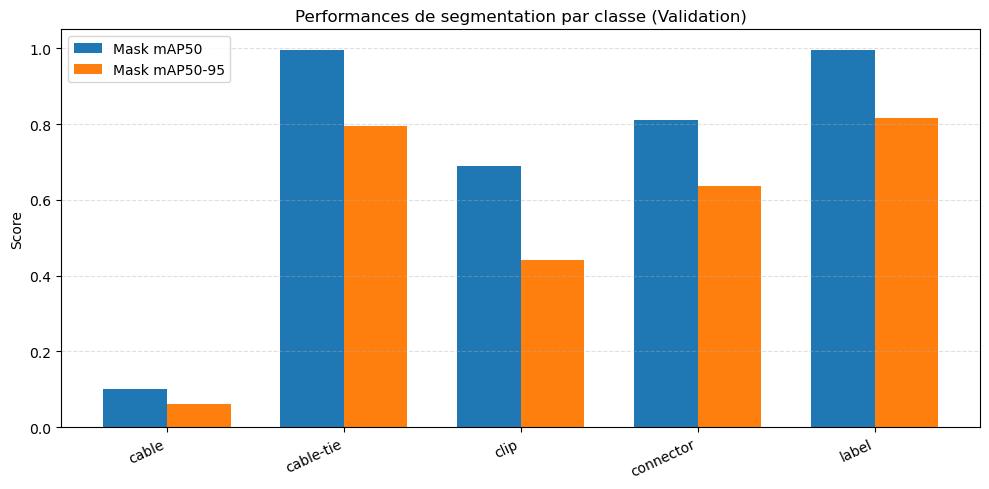

In [3]:
per_class_rows = []
ap_class_idx = getattr(val_metrics.box, "ap_class_index", range(len(model.names)))

for i, cid in enumerate(ap_class_idx):
    cid = int(cid)
    cname = model.names.get(cid, str(cid))
    b_p, b_r, b_ap50, b_ap = val_metrics.box.class_result(i)
    b_f1 = (2 * b_p * b_r / (b_p + b_r)) if (b_p + b_r) > 0 else 0.0

    row = {
        "class_id": cid,
        "class_name": cname,
        "Box_P": round(float(b_p), 4),
        "Box_R": round(float(b_r), 4),
        "Box_F1": round(float(b_f1), 4),
        "Box_mAP50": round(float(b_ap50), 4),
        "Box_mAP50_95": round(float(b_ap), 4),
    }

    if getattr(val_metrics, "seg", None) is not None:
        m_p, m_r, m_ap50, m_ap = val_metrics.seg.class_result(i)
        m_f1 = (2 * m_p * m_r / (m_p + m_r)) if (m_p + m_r) > 0 else 0.0
        row.update({
            "Mask_P": round(float(m_p), 4),
            "Mask_R": round(float(m_r), 4),
            "Mask_F1": round(float(m_f1), 4),
            "Mask_mAP50": round(float(m_ap50), 4),
            "Mask_mAP50_95": round(float(m_ap), 4),
        })

    per_class_rows.append(row)

df_per_class = pd.DataFrame(per_class_rows)
display(df_per_class)

if not df_per_class.empty and "Mask_mAP50" in df_per_class.columns:
    fig, ax = plt.subplots(figsize=(10, 5))
    x = np.arange(len(df_per_class))
    width = 0.36
    ax.bar(x - width/2, df_per_class["Mask_mAP50"], width, label="Mask mAP50")
    ax.bar(x + width/2, df_per_class["Mask_mAP50_95"], width, label="Mask mAP50-95")
    ax.set_xticks(x)
    ax.set_xticklabels(df_per_class["class_name"], rotation=25, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("Performances de segmentation par classe (Validation)")
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

## Bloc 4 — Métriques au pixel près (`IoU`, `Dice`, `Pixel Precision`, `Pixel Recall`, `Pixel Accuracy`)

In [4]:
def polygon_to_mask(coords_norm: list[float], h: int, w: int) -> np.ndarray:
  pts = np.array(coords_norm, dtype=np.float32).reshape(-1, 2)
  pts[:, 0] *= w
  pts[:, 1] *= h
  mask = np.zeros((h, w), dtype=np.uint8)
  cv2.fillPoly(mask, [pts.astype(np.int32)], 1)
  return mask


def resolve_split_img_dir(cfg: dict, yaml_path: Path, split: str) -> Path | None:
  root = yaml_path.parent
  candidates = []

  # 1. Chemin déclaré dans data.yaml (ex: ../valid/images ou valid/images)
  entry = cfg.get(split)
  if entry:
    p = Path(entry)
    if p.is_absolute():
      candidates.append(p)
    else:
      base = Path(cfg.get("path", root))
      if not base.is_absolute():
        base = (root / base).resolve()
      candidates.append((base / p).resolve())
      candidates.append((root / p).resolve())

  # 2. Fallbacks standards ("val" -> "valid/images")
  folder_names = ["valid", "val"] if split == "val" else [split]
  for fn in folder_names:
    candidates.append((root / fn / "images").resolve())
    candidates.append((root / fn).resolve())

  for c in candidates:
    if c.exists() and c.is_dir():
      return c
  return None


def get_split_images_and_labels(cfg: dict, yaml_path: Path, split: str):
  img_dir = resolve_split_img_dir(cfg, yaml_path, split)
  if img_dir is None:
    print(f"Dossier introuvable pour le split '{split}'.")
    return []

  # Les labels sont dans ../labels (si img_dir est .../images) ou dans .../labels
  if img_dir.name.lower() == "images":
    lbl_dir = img_dir.parent / "labels"
  else:
    lbl_dir = (
        img_dir / "labels" if (img_dir / "labels").exists() else img_dir.parent / "labels"
    )

  exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
  imgs = sorted([
      p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in exts
  ])
  return [(im_p, lbl_dir / f"{im_p.stem}.txt") for im_p in imgs]


eval_pairs = get_split_images_and_labels(data_cfg, DATA_YAML, "val")
print(f"Images de validation trouvées : {len(eval_pairs)}")
pixel_records = []

for im_p, txt_p in eval_pairs:
  im = cv2.imread(str(im_p))
  if im is None:
    continue
  h, w = im.shape[:2]
  gt_mask = np.zeros((h, w), dtype=np.uint8)
  if txt_p.exists():
    for ln in txt_p.read_text(encoding="utf-8").splitlines():
      parts = ln.strip().split()
      coords = [float(x) for x in parts[1:]]
      if len(coords) >= 6 and len(coords) % 2 == 0:
        gt_mask = np.maximum(gt_mask, polygon_to_mask(coords, h, w))

  pred_mask = np.zeros((h, w), dtype=np.uint8)
  res = model.predict(source=str(im_p), conf=0.25, imgsz=640, verbose=False)[0]
  if res.masks is not None:
    for m in res.masks.data.cpu().numpy():
      m_bin = cv2.resize(
          (m > 0.5).astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST
      )
      pred_mask = np.maximum(pred_mask, m_bin)

  tp = int(np.logical_and(pred_mask == 1, gt_mask == 1).sum())
  fp = int(np.logical_and(pred_mask == 1, gt_mask == 0).sum())
  fn = int(np.logical_and(pred_mask == 0, gt_mask == 1).sum())
  tn = int(np.logical_and(pred_mask == 0, gt_mask == 0).sum())

  iou = (
      tp / (tp + fp + fn)
      if (tp + fp + fn) > 0
      else (1.0 if (tp + fp + fn) == 0 else 0.0)
  )
  dice = (
      (2 * tp) / (2 * tp + fp + fn)
      if (2 * tp + fp + fn) > 0
      else (1.0 if (tp + fp + fn) == 0 else 0.0)
  )
  p_prec = tp / (tp + fp) if (tp + fp) > 0 else (1.0 if fn == 0 else 0.0)
  p_rec = tp / (tp + fn) if (tp + fn) > 0 else (1.0 if fp == 0 else 0.0)
  p_acc = (tp + tn) / max(1, (tp + fp + fn + tn))

  pixel_records.append({
      "image": im_p.name,
      "IoU": iou,
      "Dice": dice,
      "Pixel_Precision": p_prec,
      "Pixel_Recall": p_rec,
      "Pixel_Accuracy": p_acc,
  })

df_pixel = pd.DataFrame(pixel_records)
if not df_pixel.empty:
  summary_px = []
  for col in [
      "IoU",
      "Dice",
      "Pixel_Precision",
      "Pixel_Recall",
      "Pixel_Accuracy",
  ]:
    summary_px.append({
        "metric": col,
        "mean": round(float(df_pixel[col].mean()), 4),
        "median": round(float(df_pixel[col].median()), 4),
        "std": round(float(df_pixel[col].std()), 4),
        "min": round(float(df_pixel[col].min()), 4),
        "max": round(float(df_pixel[col].max()), 4),
    })
  display(pd.DataFrame(summary_px))

Images de validation trouvées : 22


,metric,mean,median,std,min,max
0,IoU,0.6841,0.7606,0.3022,0.0000,1.0
1,Dice,0.7633,0.8640,0.2927,0.0000,1.0
2,Pixel_Precision,0.7793,0.8966,0.2996,0.0000,1.0
3,Pixel_Recall,0.7958,0.9576,0.3184,0.0000,1.0
4,Pixel_Accuracy,0.9595,0.9783,0.0446,0.8491,1.0


## Bloc 5 — Analyse selon le seuil de confiance (`conf`) et seuil optimal (`F1` max)

Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
val: Fast image access  (ping: 0.00.0 ms, read: 175.5133.7 MB/s, size: 30.7 KB)
val: Scanning D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connectors segmen.v1i.yolov8\valid\labels.cache... 22 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 22/22  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.2s3.7ss
                   all         22        106      0.899      0.667       0.78      0.593      0.766      0.679      0.759      0.582
Speed: 1.9ms preprocess, 211.8ms inference, 0.0ms loss, 3.6ms postprocess per image
Ultralytics 8.4.26  Python-3.12.7 torch-2.11.0+cpu CPU (Intel Core i5-10210U 1.60GHz)
val: Fast image access  (ping: 0.00.0 ms, read: 100.947.6 MB/s, size: 38.5 KB)
val: Scanning D:\S5\Projet_d_expertise\projet\data\processed\wiring harness connecto

,conf_threshold,Mask_Precision,Mask_Recall,Mask_F1,Mask_mAP50
0,0.10,0.7658,0.6795,0.7201,0.7592
1,0.20,0.7658,0.6795,0.7201,0.7751
2,0.25,0.7658,0.6795,0.7201,0.7540
3,0.35,0.7658,0.6795,0.7201,0.7498
4,0.50,0.8850,0.6440,0.7455,0.7627
5,0.65,0.8608,0.4746,0.6118,0.6784
6,0.75,0.6682,0.4556,0.5418,0.5714


Seuil de confiance optimal (Mask F1 max) : conf = 0.5 (F1 = 0.7455)


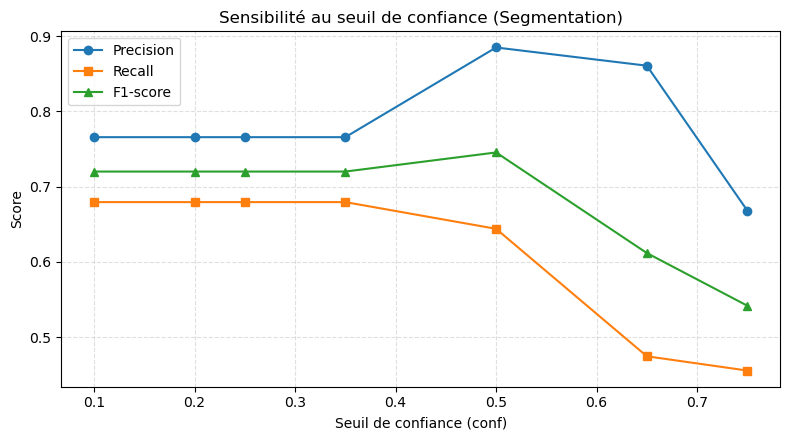

In [5]:
thresholds = [0.10, 0.20, 0.25, 0.35, 0.50, 0.65, 0.75]
conf_rows = []

for th in thresholds:
    r = model.val(data=str(DATA_YAML), split="val", conf=th, iou=0.5, imgsz=640, batch=8, workers=0, plots=False, verbose=False)
    mp = float(r.seg.mp) if getattr(r, "seg", None) is not None else float(r.box.mp)
    mr = float(r.seg.mr) if getattr(r, "seg", None) is not None else float(r.box.mr)
    f1 = (2 * mp * mr / (mp + mr)) if (mp + mr) > 0 else 0.0
    map50 = float(r.seg.map50) if getattr(r, "seg", None) is not None else float(r.box.map50)
    conf_rows.append({
        "conf_threshold": th,
        "Mask_Precision": round(mp, 4),
        "Mask_Recall": round(mr, 4),
        "Mask_F1": round(f1, 4),
        "Mask_mAP50": round(map50, 4),
    })

df_conf = pd.DataFrame(conf_rows)
best_row = df_conf.loc[df_conf["Mask_F1"].idxmax()]
display(df_conf)
print(f"Seuil de confiance optimal (Mask F1 max) : conf = {best_row['conf_threshold']} (F1 = {best_row['Mask_F1']})")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df_conf["conf_threshold"], df_conf["Mask_Precision"], marker="o", label="Precision")
ax.plot(df_conf["conf_threshold"], df_conf["Mask_Recall"], marker="s", label="Recall")
ax.plot(df_conf["conf_threshold"], df_conf["Mask_F1"], marker="^", label="F1-score")
ax.set_xlabel("Seuil de confiance (conf)")
ax.set_ylabel("Score")
ax.set_title("Sensibilité au seuil de confiance (Segmentation)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

## Bloc 6 — Mesure de latence, temps d'inférence et débit (FPS)

In [6]:
sample_paths = [p for p, _ in eval_pairs[:20]]
if sample_paths:
    # Warmup
    _ = model.predict(source=str(sample_paths[0]), imgsz=640, verbose=False)

    latencies_ms = []
    for p in sample_paths:
        t0 = time.perf_counter()
        _ = model.predict(source=str(p), imgsz=640, verbose=False)
        dt_ms = (time.perf_counter() - t0) * 1000.0
        latencies_ms.append(dt_ms)

    arr = np.array(latencies_ms)
    df_speed = pd.DataFrame([{
        "nb_images_testees": len(arr),
        "mean_ms": round(float(arr.mean()), 2),
        "median_ms": round(float(np.median(arr)), 2),
        "p95_ms": round(float(np.percentile(arr, 95)), 2),
        "min_ms": round(float(arr.min()), 2),
        "max_ms": round(float(arr.max()), 2),
        "fps_moyen": round(1000.0 / float(arr.mean()), 2),
    }])
    display(df_speed)

,nb_images_testees,mean_ms,median_ms,p95_ms,min_ms,max_ms,fps_moyen
0,20,202.21,196.46,319.61,135.64,368.1,4.95


## Bloc 7 — Visualisation qualitative des prédictions (masques, boîtes, classes et scores)

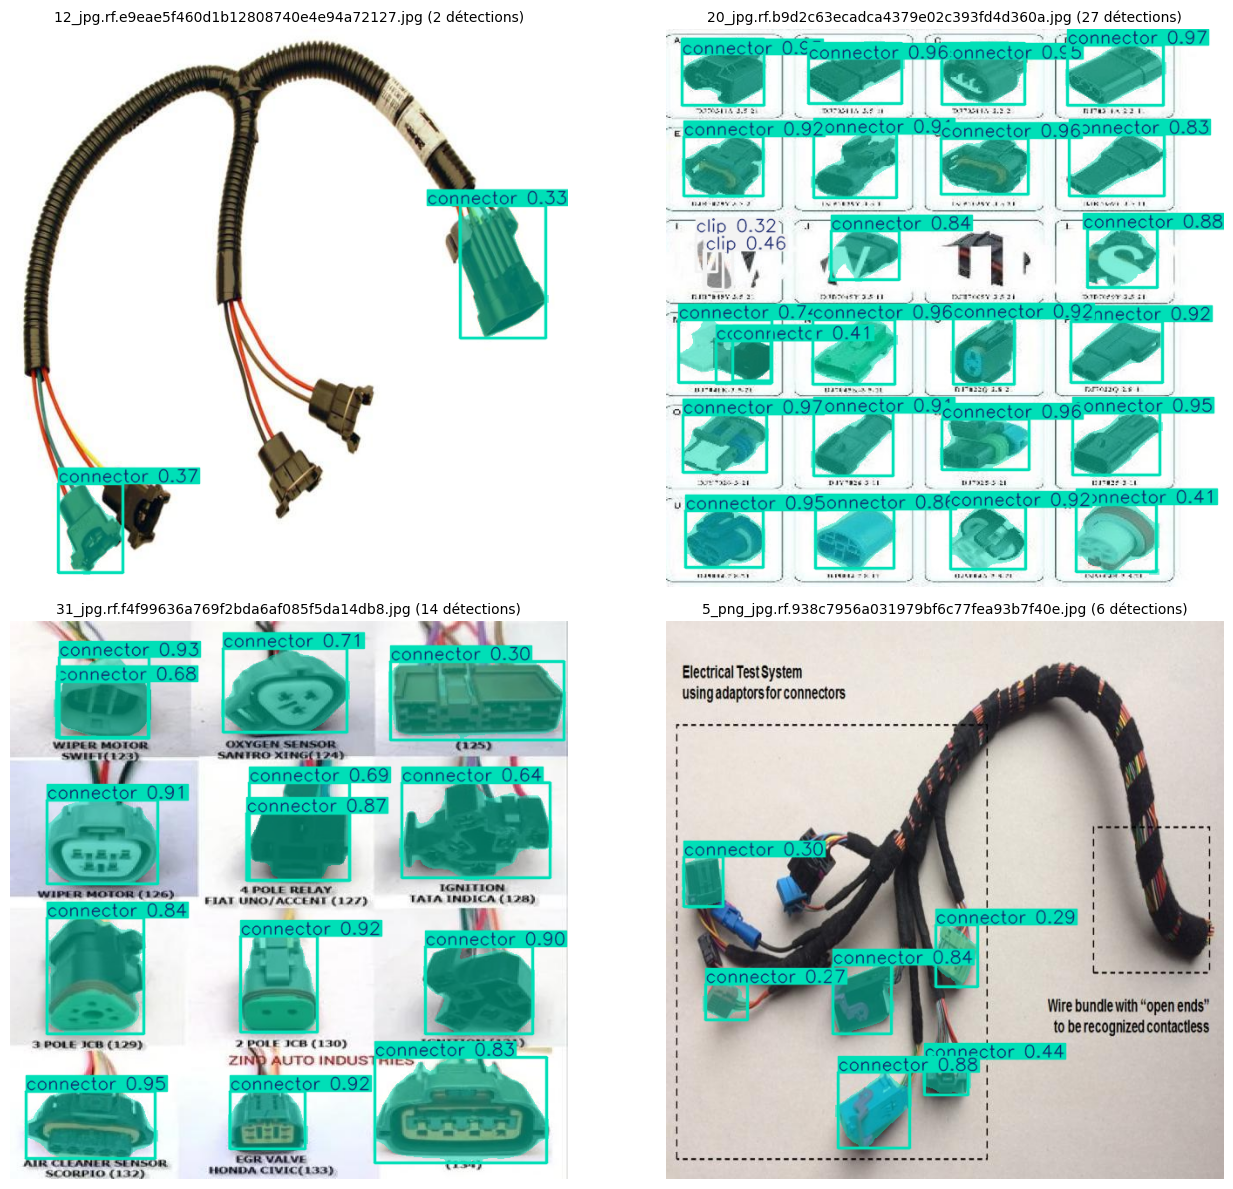

In [7]:
vis_paths = [p for p, _ in eval_pairs[:4]]
if vis_paths:
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.reshape(-1)
    for ax, p in zip(axes, vis_paths):
        res = model.predict(source=str(p), conf=0.25, imgsz=640, verbose=False)[0]
        plotted_bgr = res.plot()  # inclut masques, boîtes, classes et scores
        ax.imshow(cv2.cvtColor(plotted_bgr, cv2.COLOR_BGR2RGB))
        nb_det = len(res.boxes) if res.boxes is not None else 0
        ax.set_title(f"{p.name} ({nb_det} détections)", fontsize=10)
        ax.axis("off")
    for ax in axes[len(vis_paths):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()